# Onde os atrasos se concentram?
## Panorama geográfico para decidir os próximos experimentos

**Base:** pedidos reais que você manteve em `Dados/dataset_ml.csv`; as coordenadas vêm de
`datasets_engineering.csv`, ligadas por `order_id`, sem multiplicar pedidos.

1. Conferir cobertura geográfica e rótulos.
2. Comparar **quantidade** e **taxa** de atraso no mapa de calor.
3. Explorar pontos por **situação da entrega** ou **UF**, com filtros interativos.
4. Comparar **SP**, **Sudeste sem SP**, **Nordeste**, **Sul**, **Norte** e **Centro-Oeste**, cruzados com distância.

Nenhum CSV de entrada, partição ou modelo será modificado. Os grupos são exploratórios;
comportamentos diferentes também podem ser aprendidos por um modelo único com região e distância.
Para escolher grupos/modelos, repita a análise **somente no treino**, preservando o teste para a avaliação final.

**Como executar:** selecione o Python de `.venv-pipeline` no notebook e execute todas as células.
Mapas HTML usam internet para bibliotecas/cartografia; as figuras PNG abaixo ficam disponíveis offline.

In [1]:
from pathlib import Path
import json, math, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm, to_hex
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
import folium
from folium.plugins import HeatMap
from branca.colormap import LinearColormap
from branca.element import MacroElement, Template
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Dados/dataset_ml.csv').is_file())
EDA = RAIZ / 'src' / 'eda'
SAIDA = EDA / 'graficos'
SAIDA.mkdir(parents=True, exist_ok=True)

# Altere somente este bloco e execute novamente.
LOCALIZACAO = 'customer'      # 'customer' = destino; 'seller' = origem.
LIMITE_KM = 500               # <= limite vs > limite; 500 pertence ao primeiro grupo.
PARTICAO = 'todas'            # 'todas', 'treino', 'validacao' ou 'teste'.
ROTULOS = 'todos'             # 'todos', 'datas' ou 'pln'.
CELULA_GRAUS = 0.25           # Resolução da grade geográfica; não é distância em km.
MIN_PEDIDOS_CELULA = 30       # Não colore taxas com menos pedidos.
MIN_PEDIDOS_GRUPO = 100       # Sinaliza grupos pequenos na tabela; não os exclui.

assert LOCALIZACAO in ['customer', 'seller']
assert PARTICAO in ['todas', 'treino', 'validacao', 'teste']
assert ROTULOS in ['todos', 'datas', 'pln']
assert LIMITE_KM > 0 and CELULA_GRAUS > 0 and MIN_PEDIDOS_CELULA >= 1
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 13})
pd.set_option('display.max_rows', 40)

### Base e grupos sem sobreposição
Por padrão, a região é a **UF do cliente**, e o ponto é a coordenada média do CEP do cliente;
não representa endereço exato. Para explorar a origem, mude `LOCALIZACAO` para `seller`.
**SP significa o estado inteiro**, não somente a capital. O Sudeste exclui SP neste agrupamento.
Norte e Centro-Oeste permanecem na análise para não omitir pedidos.

In [2]:
ARQUIVOS = [RAIZ / 'Dados/dataset_ml.csv', RAIZ / 'Dados/datasets_engineering.csv']
def sha(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()
HASHES_ANTES = {str(p): sha(p) for p in ARQUIVOS}
ml = pd.read_csv(ARQUIVOS[0], low_memory=False)
coords = pd.read_csv(ARQUIVOS[1], usecols=['order_id', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng'])
assert ml.order_id.is_unique and coords.order_id.is_unique, 'IDs duplicados: revisar antes da EDA.'
base = ml.merge(coords, on='order_id', how='left', validate='one_to_one', indicator=True)
assert len(base) == len(ml)
sem_correspondencia = int(base['_merge'].ne('both').sum())
base = base.drop(columns='_merge')
base['uf'] = base[f'{LOCALIZACAO}_state'].astype('string').str.upper().str.strip()
base['lat'] = pd.to_numeric(base[f'{LOCALIZACAO}_lat'], errors='coerce')
base['lng'] = pd.to_numeric(base[f'{LOCALIZACAO}_lng'], errors='coerce')
base['delay_status'] = pd.to_numeric(base.delay_status, errors='coerce')
base['distance_customer_seller'] = pd.to_numeric(base.distance_customer_seller, errors='coerce')

REGIOES = {'SP': 'São Paulo', 'RJ': 'Sudeste sem SP', 'MG': 'Sudeste sem SP', 'ES': 'Sudeste sem SP',
           **dict.fromkeys(['PR','SC','RS'], 'Sul'),
           **dict.fromkeys(['BA','SE','AL','PE','PB','RN','CE','PI','MA'], 'Nordeste'),
           **dict.fromkeys(['AC','AM','RR','RO','PA','AP','TO'], 'Norte'),
           **dict.fromkeys(['GO','MT','MS','DF'], 'Centro-Oeste')}
ORDEM_REGIOES = ['São Paulo','Sudeste sem SP','Nordeste','Sul','Norte','Centro-Oeste','UF não informada']
base['grupo_regiao'] = base.uf.map(REGIOES).fillna('UF não informada')
DISTANCIAS = [f'Até {LIMITE_KM:g} km', f'Acima de {LIMITE_KM:g} km']
distancia_valida = np.isfinite(base.distance_customer_seller) & base.distance_customer_seller.ge(0)
base['grupo_distancia'] = np.where(distancia_valida,
    np.where(base.distance_customer_seller.le(LIMITE_KM), DISTANCIAS[0], DISTANCIAS[1]), 'Distância ausente/inválida')
base['fonte_rotulo'] = base.delay_status_source.fillna('não informada')
recorte = base.copy()
if PARTICAO != 'todas': recorte = recorte.loc[recorte.particao.eq(PARTICAO)].copy()
if ROTULOS != 'todos': recorte = recorte.loc[recorte.fonte_rotulo.eq(ROTULOS)].copy()
rotulos_invalidos = int((~recorte.delay_status.isin([0,1])).sum())
analise = recorte.loc[recorte.delay_status.isin([0,1])].copy()
assert len(analise), 'Os filtros selecionados não retornaram pedidos com rótulo válido.'
analise['delay_status'] = analise.delay_status.astype(int)
analise['rotulo_pln'] = analise.fonte_rotulo.eq('pln').astype(int)
analise['dias_atraso_positivo'] = pd.to_numeric(analise.delay_in_days, errors='coerce').clip(lower=0)
assert analise.order_id.is_unique
print(f'{len(analise):,} pedidos no recorte; taxa de atraso = {analise.delay_status.mean():.2%}.')
display(analise.groupby('fonte_rotulo').agg(pedidos=('order_id','size'), atrasos=('delay_status','sum'),
                                         taxa_atraso=('delay_status','mean')))

94,644 pedidos no recorte; taxa de atraso = 8.07%.


,pedidos,atrasos,taxa_atraso
fonte_rotulo,,,
datas,93388,6380,0.068317
pln,1256,1256,1.000000


### Cobertura dos mapas
A checagem abaixo omite **apenas da visualização** coordenadas ausentes ou fora do retângulo
que contém a malha do Brasil. Isso não certifica que cada coordenada esteja no estado correto:
há CEPs/coordenadas aproximados e a malha é simplificada. As comparações por UF/região usam
o estado informado no pedido, inclusive quando o ponto não puder ser desenhado.

Contornos: [API oficial de malhas do IBGE](https://servicodados.ibge.gov.br/api/docs/malhas?versao=3),
malha simplificada das 27 UFs, período padrão da API; URL exata em `apoio/fonte_malha.json`.

In [3]:
malha = json.loads((EDA / 'apoio/br_ufs.geojson').read_text(encoding='utf-8'))
CODIGOS = dict(zip(['11','12','13','14','15','16','17','21','22','23','24','25','26','27','28','29',
                   '31','32','33','35','41','42','43','50','51','52','53'],
                  ['RO','AC','AM','RR','PA','AP','TO','MA','PI','CE','RN','PB','PE','AL','SE','BA',
                   'MG','ES','RJ','SP','PR','SC','RS','MS','MT','GO','DF']))
def aneis(feature):
    g = feature['geometry']
    polys = [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']
    return [np.asarray(p[0]) for p in polys]
for f in malha['features']:
    f['properties']['uf'] = CODIGOS[str(f['properties']['codarea'])]
todos_vertices = np.concatenate([a for f in malha['features'] for a in aneis(f)])
OESTE, SUL = todos_vertices.min(axis=0)
LESTE, NORTE = todos_vertices.max(axis=0)
geo_valida = analise.lat.between(SUL, NORTE) & analise.lng.between(OESTE, LESTE)
geo = analise.loc[geo_valida].copy()
fora_mapa = analise.loc[~geo_valida, ['order_id','uf','lat','lng','delay_status']].copy()
assert len(geo), 'Nenhum ponto válido para o mapa.'
assert len(geo) + len(fora_mapa) == len(analise)
auditoria = pd.DataFrame({'item': ['Pedidos após seus filtros','Sem correspondência de coordenadas (base inteira)',
    'Rótulos ausentes/inválidos no recorte','Pedidos representados nos mapas','Omitidos apenas dos mapas',
    'Rótulos inferidos pela PLN no recorte'],
    'quantidade': [len(analise),sem_correspondencia,rotulos_invalidos,len(geo),len(fora_mapa),int(analise.rotulo_pln.sum())]})
display(auditoria)
display(fora_mapa.head(10))
cores_uf = {uf: to_hex(plt.get_cmap('tab20')(i)) if i < 20 else to_hex(plt.get_cmap('Set2')(i-20))
            for i,uf in enumerate(sorted(REGIOES))}
cores_status = {'Em dia': '#16836b', 'Atraso pelas datas': '#d5414f', 'Atraso inferido pela PLN': '#e8a126'}
geo['situacao'] = np.where(geo.delay_status.eq(0), 'Em dia',
                          np.where(geo.rotulo_pln.eq(1), 'Atraso inferido pela PLN', 'Atraso pelas datas'))
LOCAL = 'cliente (destino)' if LOCALIZACAO == 'customer' else 'vendedor (origem)'
def contornos(ax):
    for f in malha['features']:
        for a in aneis(f):
            ax.plot(a[:,0],a[:,1],color='#98a7b7',linewidth=.45,zorder=3)
            if f['properties']['uf']=='SP': ax.plot(a[:,0],a[:,1],color='#172b4d',linewidth=1.1,zorder=4)
    ax.set(xlim=(OESTE-1,LESTE+1),ylim=(SUL-1,NORTE+1),xlabel='Longitude',ylabel='Latitude')
    ax.set_aspect(1 / np.cos(np.deg2rad(-15)))
    ax.set_facecolor('#f4f7fa')
def mapa_base():
    m=folium.Map(location=[-15.5,-51],zoom_start=4,tiles='OpenStreetMap',prefer_canvas=True)
    folium.GeoJson(malha,name='Limites das UFs — IBGE',style_function=lambda f:
        {'fillOpacity':0,'weight':.8,'color':'#536578'},tooltip=folium.GeoJsonTooltip(fields=['uf'])).add_to(m)
    m.fit_bounds([[float(SUL),float(OESTE)],[float(NORTE),float(LESTE)]])
    return m

,item,quantidade
0,Pedidos após seus filtros,94644
1,Sem correspondência de coordenadas (base inteira),0
2,Rótulos ausentes/inválidos no recorte,0
3,Pedidos representados nos mapas,94633
4,Omitidos apenas dos mapas,11
5,Rótulos inferidos pela PLN no recorte,1256


,order_id,uf,lat,lng,delay_status
686,8ad3f1d0f96992e43566c4c82c9f6c58,PR,42.184003,-8.723762,1
5360,acdbc7396e191931c263db11af241d62,PA,22.567952,-27.698087,0
7793,72fb560d115ecf3b15de9b853c02e505,PA,7.271649,-40.315884,1
9889,fa489b941eb1d4ccba665793c2dec608,PB,-7.162589,-34.799347,0
43269,1b4f6e77a7bfc8aaecb66219bac6b9eb,PA,7.271649,-40.315884,0
52187,71fecd3061e596fd59e65e9d62886535,PA,7.271649,-40.315884,0
68362,897ec6416d50126a9061626f0fc2d658,BA,13.001420,-23.583939,0
74886,eaec582d6403b30186964f6df957047e,AL,-0.483505,-28.424444,1
76354,9e5a1beaee5b0847c3254738fe668243,RJ,-11.314698,-34.725130,1
82604,89b158fc23656141a5e33e93954d025b,PA,7.271649,-40.315884,0


## 1. Mapa de calor: volume e taxa
**Volume** responde onde estão os atrasos em quantidade; não mede maior risco por pedido.
**Taxa** = atrasos / total de pedidos na mesma célula geográfica. Células com menos que
`MIN_PEDIDOS_CELULA` não recebem cor de taxa; área sem cor **não significa zero atraso**.
Cada pedido participa uma vez dos totais; a grade usa latitude/longitude e não áreas de tamanho idêntico em km².

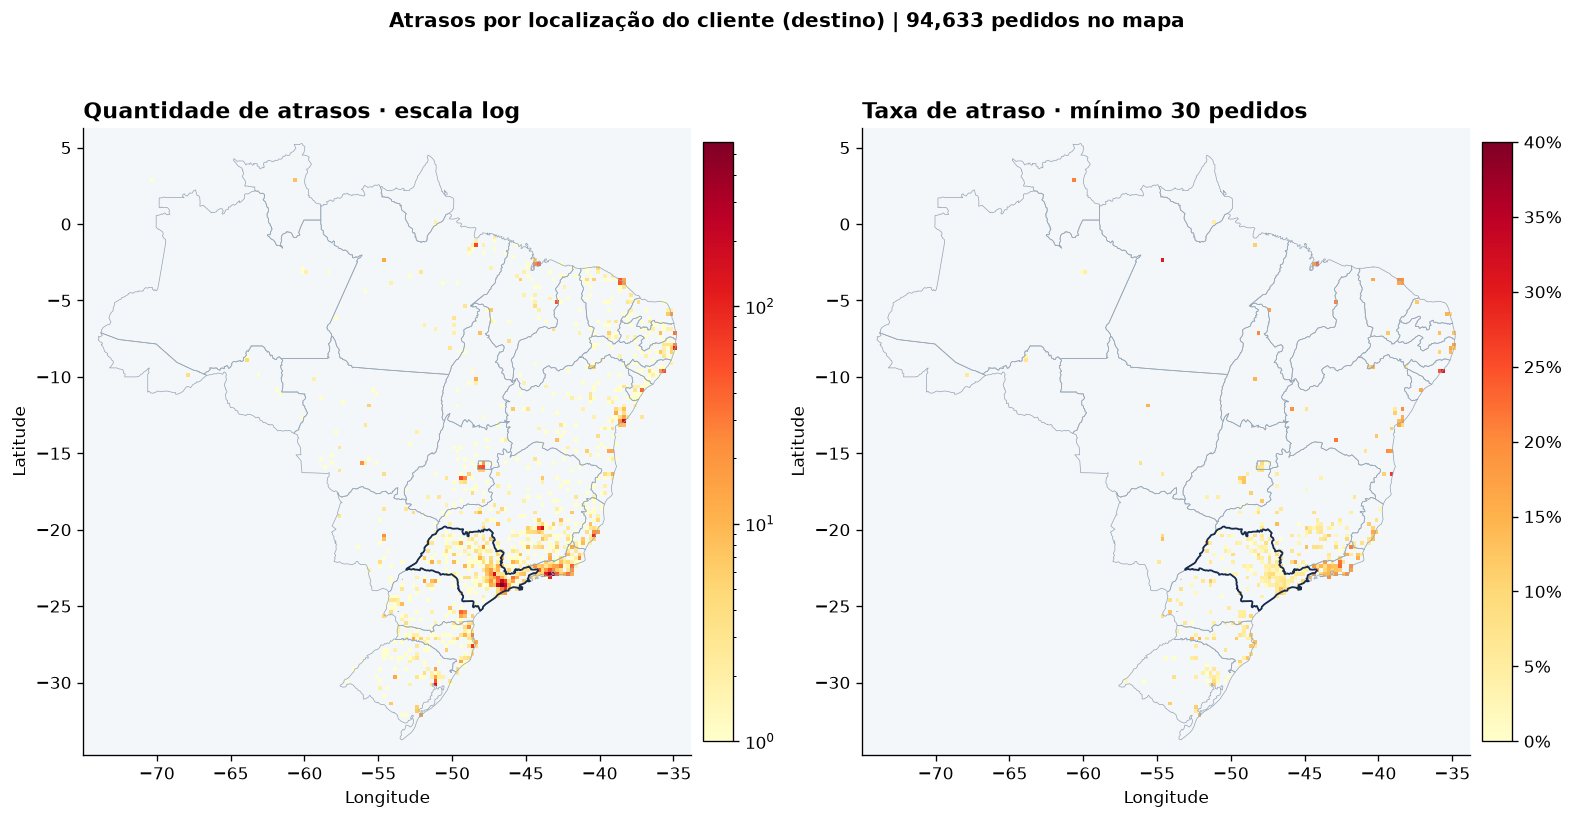

80,837 pedidos em células com volume suficiente para comparar taxas.


In [4]:
geo['cel_lat'] = np.floor(geo.lat / CELULA_GRAUS).astype(int)
geo['cel_lng'] = np.floor(geo.lng / CELULA_GRAUS).astype(int)
grade = geo.groupby(['cel_lat','cel_lng'],as_index=False).agg(
    pedidos=('order_id','size'),atrasos=('delay_status','sum'),rotulos_pln=('rotulo_pln','sum'))
grade['taxa'] = grade.atrasos / grade.pedidos
assert grade.pedidos.sum() == len(geo) and grade.atrasos.sum() == geo.delay_status.sum()
grade_taxa = grade.loc[grade.pedidos.ge(MIN_PEDIDOS_CELULA)].copy()
assert len(grade_taxa), 'Reduza MIN_PEDIDOS_CELULA ou amplie o recorte para visualizar taxas.'
MAX_TAXA = max(.1,math.ceil(grade_taxa.taxa.max()*10)/10)
def retangulo(r):
    x,y = r.cel_lng*CELULA_GRAUS,r.cel_lat*CELULA_GRAUS
    return [[x,y],[x+CELULA_GRAUS,y],[x+CELULA_GRAUS,y+CELULA_GRAUS],[x,y+CELULA_GRAUS],[x,y]]
fig,axs=plt.subplots(1,2,figsize=(13,7),constrained_layout=True)
vol=grade.loc[grade.atrasos.gt(0)]
for ax,tabela,campo,cmap,norm,titulo in [
    (axs[0],vol,'atrasos','YlOrRd',LogNorm(1,max(2,int(vol.atrasos.max()) if len(vol) else 2)), 'Quantidade de atrasos · escala log'),
    (axs[1],grade_taxa,'taxa','YlOrRd',Normalize(0,MAX_TAXA),f'Taxa de atraso · mínimo {MIN_PEDIDOS_CELULA} pedidos')]:
    pc=PolyCollection([retangulo(r) for r in tabela.itertuples()],array=tabela[campo].to_numpy(),cmap=cmap,norm=norm,edgecolors='none')
    ax.add_collection(pc);contornos(ax);ax.set_title(titulo,loc='left',fontweight='bold')
    cb=fig.colorbar(pc,ax=ax,shrink=.75,pad=.02)
    if campo=='taxa': cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,p:f'{v:.0%}'))
fig.suptitle(f'Atrasos por localização do {LOCAL} | {len(geo):,} pedidos no mapa',fontweight='bold')
fig.savefig(SAIDA/'01_mapa_calor.png',dpi=170,bbox_inches='tight');plt.show()
print(f'{int(grade_taxa.pedidos.sum()):,} pedidos em células com volume suficiente para comparar taxas.')

In [5]:
mapa_calor = mapa_base()
escala=LinearColormap(['#fff6ce','#fdc468','#f76b42','#b61932'],vmin=0,vmax=MAX_TAXA*100,
                     caption=f'Taxa de atraso (%) — células com pelo menos {MIN_PEDIDOS_CELULA} pedidos')
features=[]
for r in grade_taxa.itertuples():
    features.append({'type':'Feature','geometry':{'type':'Polygon','coordinates':[retangulo(r)]},
        'properties':{'pedidos':int(r.pedidos),'atrasos':int(r.atrasos),'taxa_pct':round(r.taxa*100,2),
                      'rotulos_pln':int(r.rotulos_pln),'cor':escala(r.taxa*100)}})
folium.GeoJson({'type':'FeatureCollection','features':features},name='Taxa por célula (normalizada)',
    style_function=lambda f:{'fillColor':f['properties']['cor'],'fillOpacity':.8,'weight':.2,'color':'#eeeeee'},
    tooltip=folium.GeoJsonTooltip(fields=['pedidos','atrasos','taxa_pct','rotulos_pln'],
                                aliases=['Pedidos','Atrasos','Taxa (%)','Rótulos PLN'])).add_to(mapa_calor)
calor=folium.FeatureGroup(name='Calor: concentração de atrasos (volume)',show=False)
atrasos=geo.loc[geo.delay_status.eq(1)].groupby(['lat','lng'],as_index=False).size()
atrasos['peso_relativo'] = atrasos['size'] / atrasos['size'].max()
HeatMap(atrasos[['lat','lng','peso_relativo']].values.tolist(),radius=17,blur=13,min_opacity=.25).add_to(calor)
calor.add_to(mapa_calor);escala.add_to(mapa_calor);folium.LayerControl(collapsed=False).add_to(mapa_calor)
mapa_calor.save(str(SAIDA/'01_mapa_calor.html'))
display(mapa_calor)

## 2. Pontos coloridos
No painel interativo, **situação da entrega** usa verde (em dia), vermelho (atraso pelas datas)
e amarelo (atraso inferido pela PLN). A opção **UF** atribui uma cor a cada estado.
Os controles filtram região, UF, distância, partição e fonte do rótulo.

Pedidos na mesma coordenada e categoria são agrupados em um ponto, com contagem no tooltip;
**não há amostragem**. Pontos de cores diferentes podem se sobrepor no mesmo CEP.
O raio indica volume; use zoom e filtros para explorar as áreas densas.

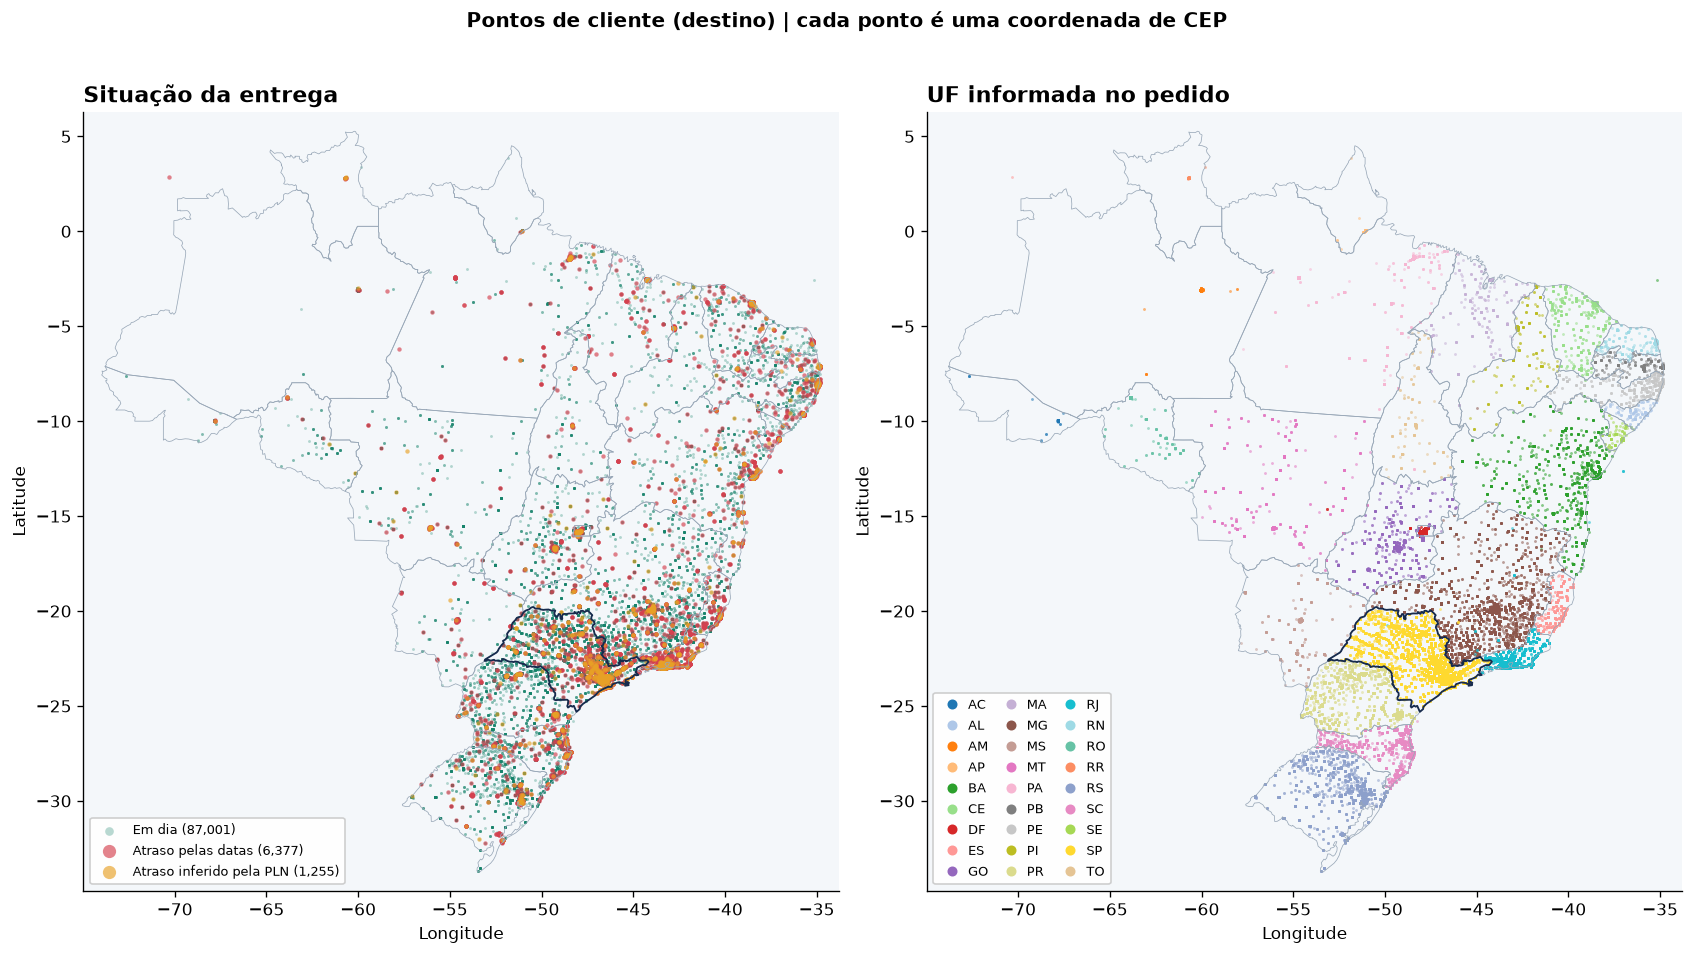

In [6]:
fig,axs=plt.subplots(1,2,figsize=(14,8),constrained_layout=True)
for label,cor in cores_status.items():
    d=geo.loc[geo.situacao.eq(label)]
    axs[0].scatter(d.lng,d.lat,s=3 if label=='Em dia' else 7,c=cor,alpha=.3 if label=='Em dia' else .65,
                   rasterized=True,label=f'{label} ({len(d):,})',linewidths=0)
for uf,cor in cores_uf.items():
    d=geo.loc[geo.uf.eq(uf)]
    axs[1].scatter(d.lng,d.lat,s=3,c=cor,alpha=.55,rasterized=True,linewidths=0)
for ax in axs:contornos(ax)
axs[0].set_title('Situação da entrega',loc='left',fontweight='bold')
axs[1].set_title('UF informada no pedido',loc='left',fontweight='bold')
axs[0].legend(loc='lower left',fontsize=8,markerscale=3,framealpha=.95)
axs[1].legend(handles=[Line2D([0],[0],marker='o',ls='',color=c,label=u,markersize=5) for u,c in cores_uf.items()],
              ncol=3,loc='lower left',fontsize=8,columnspacing=.7,handletextpad=.2,framealpha=.95)
fig.suptitle(f'Pontos de {LOCAL} | cada ponto é uma coordenada de CEP',fontweight='bold')
fig.savefig(SAIDA/'02_mapa_pontos.png',dpi=170,bbox_inches='tight');plt.show()

In [7]:
agr = geo.groupby(['lat','lng','uf','grupo_regiao','grupo_distancia','particao','fonte_rotulo','delay_status'],
                  dropna=False,as_index=False).agg(pedidos=('order_id','size'))
assert agr.pedidos.sum() == len(geo)
dados_pontos = agr.fillna('não informada').values.tolist()
mapa_pontos = mapa_base()
painel = MacroElement()
painel._template = Template(r"""
{% macro script(this, kwargs) %}
(function(){
  const map={{this.map_name}}, data={{this.dados|safe}}, ufColors={{this.cores|safe}};
  const layer=L.layerGroup().addTo(map), canvas=L.canvas({padding:.5});
  const ctrl=L.control({position:'topright'});
  ctrl.onAdd=function(){
    const box=L.DomUtil.create('div');
    box.style.cssText='background:white;padding:12px;border-radius:8px;box-shadow:0 1px 8px #888;font:12px Arial;width:245px;max-height:78vh;overflow:auto';
    box.innerHTML='<b style="font-size:15px">Explorar pedidos</b><p>Cores, região e distância</p>';
    const selects={};
    function add(name,label,values){
      const line=document.createElement('label');line.textContent=label;
      line.style.cssText='display:block;margin-top:8px';
      const sel=document.createElement('select');sel.style.cssText='width:100%;padding:4px';
      values.forEach(v=>{const opt=document.createElement('option');opt.value=v;opt.textContent=v;sel.appendChild(opt);});
      line.appendChild(sel);box.appendChild(line);selects[name]=sel;sel.onchange=render;
    }
    add('cor','Colorir por',['Situação da entrega','UF']);
    add('regiao','Região',['Todas',...new Set(data.map(r=>r[3]))]);
    add('uf','Estado',['Todos',...Object.keys(ufColors).sort()]);
    add('dist','Distância',['Todas',...new Set(data.map(r=>r[4]))]);
    add('parte','Partição',['Todas',...new Set(data.map(r=>r[5]))]);
    add('fonte','Fonte do rótulo',['Todas',...new Set(data.map(r=>r[6]))]);
    const info=document.createElement('p'),legend=document.createElement('div');box.append(info,legend);
    function render(){
      layer.clearLayers();const selected=data.filter(r=>
        (selects.regiao.value==='Todas'||r[3]===selects.regiao.value)&&
        (selects.uf.value==='Todos'||r[2]===selects.uf.value)&&
        (selects.dist.value==='Todas'||r[4]===selects.dist.value)&&
        (selects.parte.value==='Todas'||r[5]===selects.parte.value)&&
        (selects.fonte.value==='Todas'||r[6]===selects.fonte.value));
      const byUF=selects.cor.value==='UF',groups=new Map();let n=0,late=0,pln=0;
      selected.forEach(r=>{
        const color=byUF?ufColors[r[2]]:(r[7]===0?'#16836b':r[6]==='pln'?'#e8a126':'#d5414f');
        const key=[r[0],r[1],r[2],color].join('|');
        if(!groups.has(key))groups.set(key,{lat:r[0],lng:r[1],uf:r[2],color,n:0,late:0,pln:0});
        const g=groups.get(key);g.n+=r[8];g.late+=r[7]*r[8];g.pln+=(r[6]==='pln'?r[8]:0);
        n+=r[8];late+=r[7]*r[8];pln+=(r[6]==='pln'?r[8]:0);
      });
      groups.forEach(g=>L.circleMarker([g.lat,g.lng],{renderer:canvas,radius:Math.min(10,2+Math.log2(g.n+1)*.65),
        stroke:false,fillColor:g.color,fillOpacity:.7}).bindTooltip(
          '<b>'+g.uf+'</b><br>Pedidos: '+g.n+'<br>Atrasos: '+g.late+' ('+(100*g.late/g.n).toFixed(1)+'%)<br>Rótulos PLN: '+g.pln).addTo(layer));
      info.textContent=n.toLocaleString('pt-BR')+' pedidos | '+(n?100*late/n:0).toFixed(2)+'% atrasados | '+pln+' PLN';
      legend.innerHTML=byUF?Object.entries(ufColors).filter(([u])=>selected.some(r=>r[2]===u)).map(([u,c])=>
        '<span style="display:inline-block;width:55px"><i style="color:'+c+'">●</i> '+u+'</span>').join(''):
        '<span style="color:#16836b">●</span> Em dia<br><span style="color:#d5414f">●</span> Atraso pelas datas<br><span style="color:#e8a126">●</span> Atraso inferido pela PLN';
    }
    L.DomEvent.disableClickPropagation(box);L.DomEvent.disableScrollPropagation(box);
    render();return box;
  };ctrl.addTo(map);
})();
{% endmacro %}
""")
painel.map_name=mapa_pontos.get_name()
painel.dados=json.dumps(dados_pontos,ensure_ascii=False,separators=(',',':'))
painel.cores=json.dumps(cores_uf)
mapa_pontos.add_child(painel)
mapa_pontos.save(str(SAIDA/'02_mapa_pontos.html'))
display(mapa_pontos)

## 3. Região × distância: onde há diferença e quantos exemplos existem?
Taxas acompanham **número de pedidos**, **atrasos** e intervalo de Wilson de 95%.
São intervalos descritivos por pedido; repetição de vendedores/clientes e rótulos PLN
limitam sua interpretação. Zero atraso em poucos pedidos não demonstra ausência de risco.
Dias desconhecidos pela PLN ficam fora das médias de dias; sua contagem aparece separadamente.

,grupo_regiao,grupo_distancia,pedidos,atrasos,rotulos_pln,distancia_mediana_km,dias_conhecidos,media_dias_atraso_positivo,taxa_atraso_pct,ic95_inferior_pct,ic95_superior_pct,poucos_pedidos
0,Centro-Oeste,Acima de 500 km,4969,385,58,871.75,4911,0.68,7.75,7.04,8.52,False
1,Centro-Oeste,Até 500 km,363,25,3,345.20,360,0.55,6.89,4.71,9.97,False
2,Nordeste,Acima de 500 km,8782,1277,165,1907.80,8617,1.72,14.54,13.82,15.29,False
3,Nordeste,Até 500 km,197,19,5,157.40,192,0.66,9.64,6.26,14.57,False
4,Norte,Acima de 500 km,1761,177,25,2378.33,1736,1.26,10.05,8.73,11.54,False
5,Norte,Até 500 km,4,0,0,482.79,4,0.00,0.00,0.00,48.99,True
6,Sudeste sem SP,Acima de 500 km,11672,1182,137,703.86,11535,1.15,10.13,9.59,10.69,False
7,Sudeste sem SP,Até 500 km,13584,1366,228,350.32,13356,1.11,10.06,9.56,10.57,False
8,Sul,Acima de 500 km,8408,658,86,814.36,8322,0.72,7.83,7.27,8.42,False
9,Sul,Até 500 km,5101,265,46,356.85,5055,0.36,5.20,4.62,5.84,False


,uf,pedidos,atrasos,rotulos_pln,distancia_mediana_km,dias_conhecidos,media_dias_atraso_positivo,taxa_atraso_pct,ic95_inferior_pct,ic95_superior_pct,poucos_pedidos
1,AL,399,93,9,1915.76,390,2.22,23.31,19.43,27.70,False
21,RR,42,8,3,3302.87,39,4.76,19.05,9.98,33.30,True
9,MA,705,134,12,2196.18,693,1.99,19.01,16.28,22.07,False
24,SE,335,57,6,1720.99,329,2.62,17.01,13.37,21.41,False
5,CE,1279,203,31,2292.32,1248,2.19,15.87,13.97,17.98,False
16,PI,471,72,7,2061.64,464,1.98,15.29,12.32,18.82,False
18,RJ,12205,1708,242,395.72,11963,1.75,13.99,13.39,14.62,False
4,BA,3220,445,59,1421.75,3161,1.58,13.82,12.67,15.06,False
13,PA,931,117,13,2393.88,918,1.56,12.57,10.59,14.85,False
14,PB,508,63,9,2162.61,499,1.20,12.40,9.81,15.55,False


,grupo_regiao,fonte_rotulo,pedidos,atrasos,rotulos_pln,distancia_mediana_km,dias_conhecidos,media_dias_atraso_positivo,taxa_atraso_pct,ic95_inferior_pct,ic95_superior_pct,poucos_pedidos
0,Centro-Oeste,datas,5271,349,0,864.62,5271,0.67,6.62,5.98,7.32,False
1,Centro-Oeste,pln,61,61,61,872.14,0,NaN,100.00,94.08,100.00,True
2,Nordeste,datas,8809,1126,0,1884.91,8809,1.69,12.78,12.10,13.50,False
3,Nordeste,pln,170,170,170,1965.58,0,NaN,100.00,97.79,100.00,False
4,Norte,datas,1740,152,0,2377.82,1740,1.26,8.74,7.50,10.15,False
5,Norte,pln,25,25,25,2361.75,0,NaN,100.00,86.68,100.00,True
6,Sudeste sem SP,datas,24891,2183,0,484.87,24891,1.13,8.77,8.43,9.13,False
7,Sudeste sem SP,pln,365,365,365,436.16,0,NaN,100.00,98.96,100.00,False
8,Sul,datas,13377,791,0,624.93,13377,0.59,5.91,5.53,6.33,False
9,Sul,pln,132,132,132,647.62,0,NaN,100.00,97.17,100.00,False


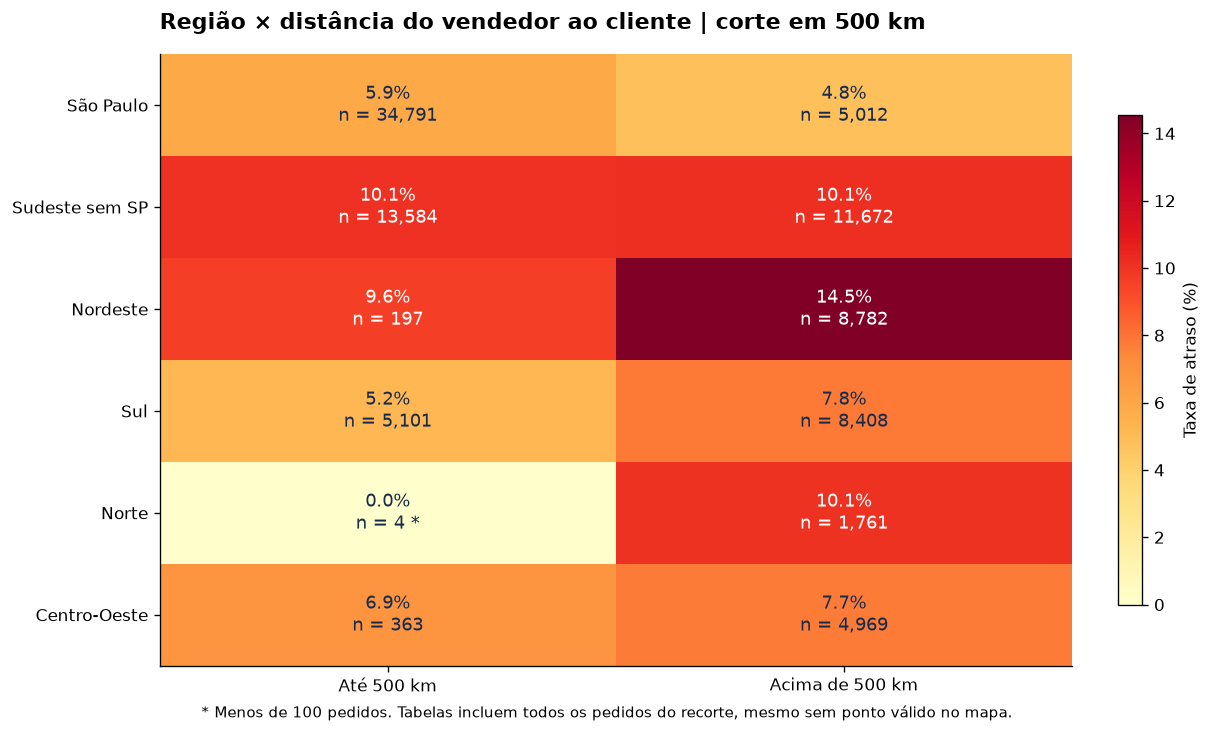

In [8]:
def resumir(d, chaves):
    r=d.groupby(chaves,dropna=False,observed=True).agg(pedidos=('order_id','size'),
        atrasos=('delay_status','sum'),rotulos_pln=('rotulo_pln','sum'),
        distancia_mediana_km=('distance_customer_seller','median'),
        dias_conhecidos=('delay_in_days','count'),media_dias_atraso_positivo=('dias_atraso_positivo','mean')).reset_index()
    n=r.pedidos.to_numpy(float);p=r.atrasos.to_numpy(float)/n;z=1.96
    centro=(p+z*z/(2*n))/(1+z*z/n)
    margem=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    r['taxa_atraso_pct']=100*p
    r['ic95_inferior_pct']=100*np.maximum(0,centro-margem)
    r['ic95_superior_pct']=100*np.minimum(1,centro+margem)
    r['poucos_pedidos']=r.pedidos.lt(MIN_PEDIDOS_GRUPO)
    return r
resumo_grupos=resumir(analise,['grupo_regiao','grupo_distancia'])
resumo_uf=resumir(analise,['uf'])
sensibilidade=resumir(analise,['grupo_regiao','fonte_rotulo'])
display(resumo_grupos.round(2))
display(resumo_uf.sort_values('taxa_atraso_pct',ascending=False).round(2))
display(sensibilidade.round(2))
assert resumo_grupos.pedidos.sum()==len(analise)
assert resumo_grupos.atrasos.sum()==analise.delay_status.sum()

linhas=[r for r in ORDEM_REGIOES if r in resumo_grupos.grupo_regiao.values]
colunas=[c for c in [*DISTANCIAS,'Distância ausente/inválida'] if c in resumo_grupos.grupo_distancia.values]
taxas=resumo_grupos.pivot(index='grupo_regiao',columns='grupo_distancia',values='taxa_atraso_pct').reindex(index=linhas,columns=colunas)
contagens=resumo_grupos.pivot(index='grupo_regiao',columns='grupo_distancia',values='pedidos').reindex(index=linhas,columns=colunas)
fig,ax=plt.subplots(figsize=(10,6),constrained_layout=True)
im=ax.imshow(taxas.to_numpy(),cmap='YlOrRd',vmin=0,vmax=max(10,float(np.nanmax(taxas))),aspect='auto')
ax.set_xticks(range(len(colunas)),colunas);ax.set_yticks(range(len(linhas)),linhas)
for i in range(len(linhas)):
    for j in range(len(colunas)):
        p,n=taxas.iloc[i,j],contagens.iloc[i,j]
        texto='Sem pedidos' if pd.isna(n) else f'{p:.1f}%\nn = {int(n):,}'+ (' *' if n<MIN_PEDIDOS_GRUPO else '')
        ax.text(j,i,texto,ha='center',va='center',fontsize=11,
                color='white' if pd.notna(p) and p>im.norm.vmax*.62 else '#172b4d')
fig.colorbar(im,ax=ax,label='Taxa de atraso (%)',shrink=.8)
ax.set_title(f'Região × distância do vendedor ao cliente | corte em {LIMITE_KM:g} km',loc='left',fontweight='bold',pad=15)
fig.supxlabel(f'* Menos de {MIN_PEDIDOS_GRUPO} pedidos. Tabelas incluem todos os pedidos do recorte, mesmo sem ponto válido no mapa.',fontsize=9)
fig.savefig(SAIDA/'03_regiao_distancia.png',dpi=170,bbox_inches='tight');plt.show()

### Antes de escolher grupos de treinamento
- Compare **taxas**, não somente a intensidade do calor de volume.
- Confira os dois lados do limite de distância na mesma região, o tamanho do grupo e seu intervalo.
- Repita com `ROTULOS='datas'`: a PLN é uma inferência, não confirmação independente de atraso.
- Repita com `PARTICAO='treino'` para decidir os grupos; use validação para comparar alternativas.
- A distância existente é geográfica entre cliente e vendedor, não rota percorrida nem transportadora real.
- A hipótese “distância curta sempre atrasa” ou “distância longa nunca atrasa” não é imposta à análise.

Os mapas não definem grupos de treino automaticamente. Compare depois um modelo único com interações
e modelos por grupo, mantendo as mesmas partições e verificando se cada grupo tem ambas as classes.

In [9]:
assert all(sha(Path(p)) == h for p,h in HASHES_ANTES.items()), 'Uma fonte foi alterada durante a execução.'
print('Fontes preservadas. Gráficos gerados:')
for p in sorted(SAIDA.iterdir()):
    if p.suffix in ['.html','.png']: print(p.relative_to(RAIZ))
print('Filtros:', {'localizacao':LOCALIZACAO,'particao':PARTICAO,'rotulos':ROTULOS,
                  'limite_km':LIMITE_KM,'min_pedidos_celula':MIN_PEDIDOS_CELULA})

Fontes preservadas. Gráficos gerados:
src\eda\graficos\01_mapa_calor.html
src\eda\graficos\01_mapa_calor.png
src\eda\graficos\02_mapa_pontos.html
src\eda\graficos\02_mapa_pontos.png
src\eda\graficos\03_regiao_distancia.png
Filtros: {'localizacao': 'customer', 'particao': 'todas', 'rotulos': 'todos', 'limite_km': 500, 'min_pedidos_celula': 30}
